In [30]:
%pip install scipy numpy matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
### Imports
import numpy as np
import matplotlib.pyplot as plt
import csv

from pathlib import Path
from datetime import datetime
from time import perf_counter
from scipy.sparse import issparse
from scipy.io import savemat, loadmat
# from tqdm.auto import tqdm

ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data" / "traffic_dataset.mat").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        f"Cannot find data/traffic_dataset.mat from {Path.cwd()}"
    )

DATA_PATH = ROOT / "data" / "traffic_dataset.mat"

In [32]:
### Extraction et formattage du dataset
def _dense(x):
    """Convertit un objet sparse ou un tableau en ndarray float."""
    return (x.toarray() if issparse(x) else np.asarray(x)).astype(float)


def _stack(cells):
    """Cell array MATLAB (1, T) de matrices (36, 48) -> ndarray (T, 36, 48)."""
    return np.stack([_dense(x) for x in cells.squeeze()])



def load_raw(path=DATA_PATH):
    m = loadmat(str(path))
    X_tr, X_te = _stack(m["tra_X_tr"]), _stack(m["tra_X_te"])  # (T, 36, 48)
    Y_tr = _dense(m["tra_Y_tr"]).T                             # (T, 36)
    Y_te = _dense(m["tra_Y_te"]).T
    A = _dense(m["tra_adj_mat"])                               # (36, 36)
    assert X_tr.shape[1:] == (36, 48) and Y_tr.shape == X_tr.shape[:2]
    return X_tr, Y_tr, X_te, Y_te, A


Pour se rendre mieux compte de notre problème et de la dépendance entre différents capteurs, on cherche à calculer une matrice permettant de modéliser cette interdépendance. Pour cela, on s'appuie sur le modèle décrit dans l'article *Spatial Auto-regressive Dependency Interpretable Learning Based on Spatial Topological Constraints*.

On formule notre problème sous la forme du problème SADL-I afin d'appliquer l'algorithme ADMM à l'optimisation des paramètres.

On note $T$ le nombre d'observations temporelles utilisées pour l'entraînement, $S$ le nombre de capteurs et $F$ le nombre de variables explicatives. On utilise les notations suivantes :

$$
X_t \in \mathbb{R}^{S\times F},
\qquad
y_t \in \mathbb{R}^{S},
$$

et

$$
D,U,\Gamma_1 \in \mathbb{R}^{S\times S},\qquad
W,V,\Gamma_2 \in \mathbb{R}^{1\times F}.
$$

La matrice $X_t$ contient les variables explicatives disponibles à l'instant $t$ pour l'ensemble des capteurs. Le vecteur $y_t$ contient les débits de circulation futurs correspondants, qui constituent les valeurs cibles de l'apprentissage.

On adopte la convention suivante pour les variables duales normalisées de l'algorithme ADMM, $\Gamma_1$ et $\Gamma_2$ :

$$
W-V+\Gamma_2,
\qquad
U-I_S+D+\Gamma_1.
$$

Lors de chaque mise à jour, toutes les variables autres que celle en cours d'optimisation sont maintenues constantes.

### Optimisation des paramètres de SADL-I

**Entrées :** $X$, $Y$, $\sigma$, $\lambda$ et le masque topologique $D_M$.

**Sorties :** $W$, $V$, $U$ et $D$.

**Initialisation :**

- $\gamma \gets 1$.
- $W \gets 0$, $V \gets 0$, $D \gets 0$, $U \gets I_S$.
- $\Gamma_1 \gets 0$, $\Gamma_2 \gets 0$.
- Choisir $\varepsilon_p > 0$ et $\varepsilon_d > 0$.

**Répéter :**

1. Sauvegarder $U_{\mathrm{old}} \gets U$ et $V_{\mathrm{old}} \gets V$.

2. Mettre à jour $W$, puis $V$, puis $U$.

3. Répéter jusqu'à convergence de la descente de gradient pour H(D) :

   $$
   \Delta_D \gets D-\eta\nabla H(D)
   $$

   $$
   D \gets
   \left[
       \left(
           \frac{\Delta_D+\Delta_D^\top}{2}
       \right)
       \odot D_M
   \right]_+
   $$

4. Calculer le résidu primal $p$ et le résidu dual $d$.

5. Mettre à jour les variables duales normalisées :

   $$
   \Gamma_1 \gets \Gamma_1 + U + D - I_S,
   \qquad
   \Gamma_2 \gets \Gamma_2 + W - V.
   $$

6. Sauvegarder $\gamma_{\mathrm{old}} \gets \gamma$, puis adapter $\gamma$ :

   $$
   \gamma \gets
   \begin{cases}
   2\gamma, & \text{si } p > 10d,\\
   \gamma/2, & \text{si } d > 10p,\\
   \gamma, & \text{sinon}.
   \end{cases}
   $$

7. Redimensionner les variables duales normalisées :

   $$
   \Gamma_1 \gets
   \frac{\gamma_{\mathrm{old}}}{\gamma}\Gamma_1,
   \qquad
   \Gamma_2 \gets
   \frac{\gamma_{\mathrm{old}}}{\gamma}\Gamma_2.
   $$

**Jusqu'à** $p < \varepsilon_p$ et $d < \varepsilon_d$, ou jusqu'au nombre maximal d'itérations.

### Mise à jour de $W$

Pour $W$, l'article nous donne une solution analytique :

$$
\boxed{
W=
\left[
\frac{1}{\sigma^2}
\sum_{t=1}^{T}
y_t^\top(I_S-D)^\top X_t
+\gamma(V-\Gamma_2)
\right]
\left[
\frac{1}{\sigma^2}
\sum_{t=1}^{T}X_t^\top X_t
+\gamma I_F
\right]^{-1}.
}
$$

In [33]:
# def update_W(X, Y, D, V, Gamma2, sigma, gamma):
#     T, S, F = X.shape
#     I = np.eye(S)

#     Matrix_1 = np.zeros(F)
#     Matrix_2 = np.zeros((F, F))

#     for t in range(T):
#         Matrix_1 += (X[t].T @ ((I - D) @ Y[t])) / sigma**2
#         Matrix_2 += (X[t].T @ X[t]) / sigma**2

#     Matrix_1 += gamma * (V - Gamma2)
#     Matrix_2 += gamma * np.eye(F)

#     W = np.linalg.solve(Matrix_2, Matrix_1)

#     return W

def update_W(X, Y, D, V, Gamma2, sigma, gamma):
    T, S, F = X.shape

    X_flat = X.reshape(T * S, F)
    target = (Y @ (np.eye(S) - D).T).reshape(T * S)

    lhs = (X_flat.T @ X_flat) / sigma**2 + gamma * np.eye(F)
    rhs = (X_flat.T @ target) / sigma**2 + gamma * (V - Gamma2)

    return np.linalg.solve(lhs, rhs)


### Mise à jour de $V$

Le sous-problème pour l'optimisation de $V$, avec $R(V)=\|V\|_1$, est :

$$
\min_V
\frac{\gamma}{2}
\left\|W-V+\Gamma_2\right\|_F^2
+\lambda\|V\|_1.
$$

En notant $Z=W+\Gamma_2$, la fonction objective s'écrit :

$$
\sum_{f=1}^{F}
\left[
\frac{\gamma}{2}(V_f-Z_f)^2
+\lambda|V_f|
\right].
$$

On peut donc minimiser chaque composante de $V$ indépendamment des autres. Pour une composante, on considère :

$$
h(v)=\frac{\gamma}{2}(v-z)^2+\lambda|v|.
$$

Pour $v\neq 0$, la dérivée dépend du signe de $v$ :

$$
h'(v)=
\begin{cases}
\gamma(v-z)+\lambda, & v>0,\\
\gamma(v-z)-\lambda, & v<0.
\end{cases}
$$

En annulant cette dérivée, on obtient :

$$
v=
\begin{cases}
z-\lambda/\gamma, & \text{si } z>\lambda/\gamma,\\
z+\lambda/\gamma, & \text{si } z<-\lambda/\gamma.
\end{cases}
$$

En v=0, la valeur absolue n'est pas dérivable, mais le premier terme de h l'est et la valeur absolue a une dérivée égale à -1 à gauche et 1 à droite. On introduit alors la notion d'ensemble sous-différentiel pour une fonction f qui nous dit que la pente a d'une tangente appartient à cet ensemble si et seulement si $$\forall x, \, ax \leq f(x)$$ Or $$\forall a \in [-1, 1], \forall v, \, av \leq |v|$$ Ainsi pour la fonction h le sous-différentiel est $$[-\gamma z - \lambda, -\gamma z + \lambda]$$. Or une fonction convexe (h l'est) atteint son minimum en un point si et seulement si son sous-différentiel y contient 0. Par conséquent, v=0 est optimal lorsque

$$
0[-\gamma z - \lambda, -\gamma z + \lambda]
\quad\Longleftrightarrow\quad
|z|\leq\frac{\lambda}{\gamma}.
$$

On obtient ainsi les trois cas suivants, correspondant à l'opérateur soft-thresholding:

$$
\boxed{
V_f=
\begin{cases}
Z_f-\lambda/\gamma,
& Z_f>\lambda/\gamma,\\[2pt]
0,
& |Z_f|\leq\lambda/\gamma,\\[2pt]
Z_f+\lambda/\gamma,
& Z_f<-\lambda/\gamma.
\end{cases}
}
$$

In [34]:
def update_V(W, Gamma2, lam, gamma):
    Z = W + Gamma2
    V = np.zeros_like(Z, dtype=float)

    threshold = lam / gamma

    for i in range(len(Z)):
        if Z[i] > threshold:
            V[i] = Z[i] - threshold
        elif Z[i] < -threshold:
            V[i] = Z[i] + threshold
        else:
            V[i] = 0.0

    return V


### Mise à jour de $U$

Le sous-problème pour trouver $U$ est :

$$
\min_{U\succ 0}
\frac{\gamma}{2}
\left\|U-I_S+D+\Gamma_1\right\|_F^2
-\log\det(U).
$$

La notation $U\succ 0$ signifie que $U$ est symétrique définie positive.

On pose $B=I_S-D-\Gamma_1$. Cette matrice est symétrique puisque $I_S$, $D$ et $\Gamma_1$ le sont. En revanche, elle n'est pas nécessairement définie positive.

Le sous-problème devient :

$$
\min_{U\succ 0}
\frac{\gamma}{2}
\left\|U-B\right\|_F^2
-\log\det(U).
$$

En utilisant $\nabla_U\log\det(U)=U^{-1}$ pour une matrice symétrique définie positive, la condition d'optimalité s'écrit :

$$
\gamma(U-B)-U^{-1}=0.
$$

On obtient donc :

$$
\gamma B=\gamma U-U^{-1}.
$$

Cette relation montre que $B$ et $U$ commutent. Étant symétriques, elles peuvent être diagonalisées dans une même base orthonormée.

On note :

$$
\gamma B=PQP^\top,
\qquad
Q=\operatorname{diag}(q_1,\ldots,q_S),
\qquad
P^\top P=I_S,
$$

et

$$
U=P\operatorname{diag}(u_1,\ldots,u_S)P^\top.
$$

En multipliant la condition d'optimalité à gauche par $P^\top$ et à droite par $P$, on obtient :

$$
\gamma\operatorname{diag}(u_1,\ldots,u_S)
-Q
-\operatorname{diag}(u_1^{-1},\ldots,u_S^{-1})
=0.
$$

Pour chaque valeur propre, cela donne :

$$
\gamma u_i-q_i-\frac{1}{u_i}=0.
$$

Puisque $u_i>0$, on peut multiplier par $u_i$ :

$$
\gamma u_i^2-q_i u_i-1=0.
$$

Les deux racines sont :

$$
u_i=
\frac{q_i\pm\sqrt{q_i^2+4\gamma}}{2\gamma}.
$$

Comme $\gamma>0$, seule la racine avec le signe $+$ est positive. Ainsi :

$$
u_i=
\frac{q_i+\sqrt{q_i^2+4\gamma}}{2\gamma}.
$$

Finalement :

$$
\boxed{
U=
\frac{1}{2\gamma}
P\left(
Q+\sqrt{Q^2+4\gamma I_S}
\right)P^\top.
}
$$


In [ ]:
def update_U(D, gamma, Gamma1, T):
    S = D.shape[0]
    I = np.eye(S)

    M = gamma * (I - D - Gamma1)

    eigenvalues, P = np.linalg.eigh(M)
    Q = np.diag(eigenvalues)

    U = 1/(2*gamma) * P @ (Q + (Q@Q + 4*gamma*T*I)**0.5) @ P.T

    return U

### Mise à jour de $D$ et choix du pas $\eta$

Pour optimiser $D$, on applique une descente de gradient projetée à la fonction $H$. Il reste à choisir le pas $\eta$.

La fonction à minimiser est :

$$
H(D)=
\frac{1}{2\sigma^2}
\sum_{t=1}^{T}
\left\|(I_S-D)y_t-X_tW^\top\right\|_2^2
+
\frac{\gamma}{2}
\left\|U-I_S+D+\Gamma_1\right\|_F^2.
$$

Son gradient s'écrit :

$$
\nabla H(D)=
-\frac{1}{\sigma^2}
\sum_{t=1}^{T}
\left[(I_S-D)y_t-X_tW^\top\right]y_t^\top
+\gamma(U-I_S+D+\Gamma_1).
$$

En développant, on obtient :

$$
\nabla H(D)=
\frac{1}{\sigma^2}
\left[
(D-I_S)\sum_{t=1}^{T}y_ty_t^\top
+
\sum_{t=1}^{T}(X_tW^\top)y_t^\top
\right]
+\gamma(U-I_S+D+\Gamma_1).
$$

Pour choisir $\eta$, on étudie la variation du gradient lorsque $D$ est perturbée de $\Delta D$, les autres variables restant constantes :

$$
\begin{aligned}
\nabla H(D+\Delta D)-\nabla H(D)
&=
\frac{1}{\sigma^2}
\Delta D\sum_{t=1}^{T}y_ty_t^\top
+\gamma\Delta D\\
&=
\Delta D
\underbrace{
\left(
\frac{1}{\sigma^2}\sum_{t=1}^{T}y_ty_t^\top
+\gamma I_S
\right)
}_{K}.
\end{aligned}
$$

La matrice $K$ est symétrique définie positive puisque $\gamma>0$. Sa norme spectrale est donc égale à sa plus grande valeur propre. On en déduit :

$$
\begin{aligned}
\|\nabla H(D+\Delta D)-\nabla H(D)\|_F
&=\|\Delta D K\|_F\\
&\leq \|\Delta D\|_F\|K\|_2\\
&=\lambda_{\max}(K)\|\Delta D\|_F.
\end{aligned}
$$

Le gradient est donc Lipschitz de constante :

$$
L=\lambda_{\max}(K).
$$

En notant $Y\in\mathbb{R}^{T\times S}$ la matrice dont la ligne $t$ est $y_t^\top$, on a :

$$
Y^\top Y=\sum_{t=1}^{T}y_ty_t^\top.
$$

Ainsi :

$$
L=
\frac{\lambda_{\max}(Y^\top Y)}{\sigma^2}+\gamma.
$$

On choisit alors le pas :

$$
\boxed{
\eta=\frac{1}{L}
=
\frac{1}{
\lambda_{\max}(Y^\top Y)/\sigma^2+\gamma
}.
}
$$

Chaque itération de descente de gradient projetée s'écrit :

$$
D^{(k+1)}
=
\Pi_{\mathcal C}
\left(
D^{(k)}-\eta\nabla H(D^{(k)})
\right),
$$

où $\Pi_{\mathcal C}$ désigne la projection sur l'ensemble des matrices respectant les contraintes topologiques, la symétrie, la non-négativité et la diagonale nulle.

In [36]:
def step_gradient_descent_D(X, Y, D, W, U, Gamma1, A, sigma, gamma, eta):

    L = np.linalg.eigvalsh(Y.T @ Y)[-1] / sigma**2 + gamma

    if eta is None:
        eta = 1.0 / L 

    def gradient_H(X, Y, D, W, U, Gamma1, sigma, gamma):
        T, S, F = X.shape
        I = np.eye(S)  

        gradient = np.zeros((S, S))

        for t in range(T):
            residual = (I - D) @ Y[t] - X[t] @ W

            gradient -= np.outer(residual, Y[t]) / sigma**2

        gradient += gamma * (U - I + D + Gamma1)

        return gradient

    grad = gradient_H(X, Y, D, W, U, Gamma1, sigma, gamma)

    delta_D = D - eta * grad

    # Enforce symmetry
    delta_D = (delta_D + delta_D.T) / 2

    # Keep only known connections
    delta_D = delta_D * (A != 0)

    # Enforce nonnegative weights and zero diagonal
    delta_D = np.maximum(delta_D, 0.0)
    np.fill_diagonal(delta_D, 0.0)

    return delta_D


def gradient_descent_D(X, Y, D, W, U, Gamma1, A, sigma, gamma, eta, tol=1e-6, max_iter=10000):
    difference = np.inf

    S = D.shape[0]
    I = np.eye(S)
    YY = (Y.T @ Y) / sigma**2
    XY = ((X @ W).T @ Y) / sigma**2
    constant = XY - YY + gamma * (U - I + Gamma1)

    if eta is None:
        L = np.linalg.eigvalsh(YY)[-1] + gamma
        eta = 1.0 / L

    mask = (A != 0) & (A.T != 0)
    np.fill_diagonal(mask, False)

    for iteration in range(max_iter):
        # Equivalent gradient, using only small matrices
        gradient = D @ YY + gamma * D + constant

        D_new = D - eta * gradient

        D_new = (D_new + D_new.T) / 2
        D_new *= mask
        np.maximum(D_new, 0.0, out=D_new)

        difference = np.linalg.norm(D_new - D, ord="fro")
        D = D_new

        if difference < tol:
            break

    return D


### Calcul des résidus primal et dual

Le modèle a les contraintes suivantes :

$$
U = I_S-D,
\qquad
V = W.
$$

Afin de calculer les résidus primal et dual selon la méthode présentée par Boyd, on écrit ces contraintes sous la forme :

$$
A_Bx+B_Bz-c=0.
$$

Les variables $x$ et $z$ étant des vecteurs colonnes, on vectorise les matrices $D$ et $U$ en empilant leurs colonnes. En notant $D_j$ et $U_j$ leurs colonnes respectives, on obtient :

$$
D=
\begin{pmatrix}
D_1 & D_2 & \cdots & D_S
\end{pmatrix}
\quad\Longrightarrow\quad
\operatorname{vec}(D)=
\begin{pmatrix}
D_1\\
D_2\\
\vdots\\
D_S
\end{pmatrix},
$$

et

$$
U=
\begin{pmatrix}
U_1 & U_2 & \cdots & U_S
\end{pmatrix}
\quad\Longrightarrow\quad
\operatorname{vec}(U)=
\begin{pmatrix}
U_1\\
U_2\\
\vdots\\
U_S
\end{pmatrix}.
$$

On définit alors :

$$
x=
\begin{pmatrix}
\operatorname{vec}(D)\\
W^\top
\end{pmatrix},
\qquad
z=
\begin{pmatrix}
\operatorname{vec}(U)\\
V^\top
\end{pmatrix}.
$$

Les matrices correspondant à la formulation de Boyd sont :

$$
A_B=
\begin{pmatrix}
I_{S^2} & 0\\
0 & I_F
\end{pmatrix},
\qquad
B_B=
\begin{pmatrix}
I_{S^2} & 0\\
0 & -I_F
\end{pmatrix},
\qquad
c=
\begin{pmatrix}
\operatorname{vec}(I_S)\\
0_F
\end{pmatrix}.
$$

Cette écriture permet de retrouver les contraintes initiales :

$$
A_Bx+B_Bz-c
=
\begin{pmatrix}
\operatorname{vec}(D+U-I_S)\\
W^\top-V^\top
\end{pmatrix}
=
\begin{pmatrix}
0_{S^2}\\
0_F
\end{pmatrix}.
$$

#### Résidu primal

Dans l'algorithme ADMM, le résidu primal à l'itération $k$ est défini par :

$$
r^k=A_Bx^k+B_Bz^k-c.
$$

Sa norme s'écrit donc :

$$
\begin{aligned}
\|r^k\|_2
&=
\left\|
\begin{pmatrix}
\operatorname{vec}(D^k+U^k-I_S)\\
(W^k)^\top-(V^k)^\top
\end{pmatrix}
\right\|_2\\
&=
\sqrt{
\|D^k+U^k-I_S\|_F^2
+
\|(W^k)^\top-(V^k)^\top\|_2^2
}.
\end{aligned}
$$

#### Résidu dual

Pour le regroupement de variables défini ci-dessus, le résidu dual est :

$$
s^k=\rho A_B^\top B_B(z^k-z^{k-1}),
$$

où le paramètre $\rho$ de Boyd correspond au paramètre $\gamma$ utilisé dans notre algorithme.

Puisque :

$$
A_B^\top B_B=
\begin{pmatrix}
I_{S^2} & 0\\
0 & -I_F
\end{pmatrix},
$$

on obtient :

$$
s^k=
\gamma
\begin{pmatrix}
\operatorname{vec}(U^k-U^{k-1})\\
-\bigl((V^k)^\top-(V^{k-1})^\top\bigr)
\end{pmatrix}.
$$

Sa norme est donc :

$$
\|s^k\|_2
=
\gamma
\sqrt{
\|U^k-U^{k-1}\|_F^2
+
\|(V^k)^\top-(V^{k-1})^\top\|_2^2
}.
$$

#### Critère d'arrêt

On utilise ainsi les deux quantités scalaires suivantes :

$$
\boxed{
p=
\sqrt{
\|D+U-I_S\|_F^2
+
\|W^\top-V^\top\|_2^2
}.
}
$$

$$
\boxed{
d=
\gamma
\sqrt{
\|U-U_{\mathrm{old}}\|_F^2
+
\|V^\top-V_{\mathrm{old}}^\top\|_2^2
}.
}
$$

L'algorithme s'arrête lorsque :

$$
p<\varepsilon_p
\qquad\text{et}\qquad
d<\varepsilon_d.
$$

Si $\gamma$ est adapté au cours des itérations, le résidu dual est calculé avec la valeur de $\gamma$ utilisée pour l'itération courante, avant son adaptation.

In [37]:
def calculate_primal_dual_residuals(U, D, W, V, gamma, U_old, V_old):
    S = D.shape[0]
    primal = np.sqrt(
    np.sum((D + U - np.eye(S))**2)
        + np.sum((W - V)**2)
    )
    dual = gamma * np.sqrt(
        np.sum((U - U_old)**2)
        + np.sum((V - V_old)**2)
    )
    return primal, dual


### Voici à nouveau le pseudo-code de l'algorithme SADL-I

**Entrées :** $X$, $Y$, $\sigma$, $\lambda$ et le masque topologique $D_M$.

**Sorties :** $W$, $V$, $U$ et $D$.

**Initialisation :**

- $\gamma \gets 1$.
- $W \gets 0$, $V \gets 0$, $D \gets 0$, $U \gets I_S$.
- $\Gamma_1 \gets 0$, $\Gamma_2 \gets 0$.
- Choisir $\varepsilon_p > 0$ et $\varepsilon_d > 0$.

**Répéter :**

1. Sauvegarder $U_{\mathrm{old}} \gets U$ et $V_{\mathrm{old}} \gets V$.

2. Mettre à jour $W$, puis $V$, puis $U$.

3. Répéter jusqu'à convergence interne :

   $$
   \Delta_D \gets D-\eta\nabla H(D)
   $$

   $$
   D \gets
   \left[
       \left(
           \frac{\Delta_D+\Delta_D^\top}{2}
       \right)
       \odot D_M
   \right]_+
   $$

   Imposer une diagonale nulle à $D$.

4. Calculer le résidu primal $p$ et le résidu dual $d$.

5. Mettre à jour les variables duales normalisées :

   $$
   \Gamma_1 \gets \Gamma_1 + U + D - I_S,
   \qquad
   \Gamma_2 \gets \Gamma_2 + W - V.
   $$

6. Sauvegarder $\gamma_{\mathrm{old}} \gets \gamma$, puis adapter $\gamma$ :

   $$
   \gamma \gets
   \begin{cases}
   2\gamma, & \text{si } p > 10d,\\
   \gamma/2, & \text{si } d > 10p,\\
   \gamma, & \text{sinon}.
   \end{cases}
   $$

7. Redimensionner les variables duales normalisées :

   $$
   \Gamma_1 \gets
   \frac{\gamma_{\mathrm{old}}}{\gamma}\Gamma_1,
   \qquad
   \Gamma_2 \gets
   \frac{\gamma_{\mathrm{old}}}{\gamma}\Gamma_2.
   $$

**Jusqu'à** $p < \varepsilon_p$ et $d < \varepsilon_d$, ou jusqu'au nombre maximal d'itérations.

In [38]:
def optimise_sadl(X, Y, sigma, lamda, A, eta, epsilon_p=1e-6, epsilon_d=1e-6, max_iter=1000):
    # Variable extraction
    T, S, F = X.shape

    # Initialisation step
    gamma = 1.0

    W = np.zeros(F)
    V = np.zeros(F)
    D = np.zeros((S, S))
    U = np.eye(S)

    Gamma1 = np.zeros((S, S))
    Gamma2 = np.zeros(F)

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    csv_path = ROOT / "results" / f"sadl_history_{timestamp}.csv"

    csv_path = Path(csv_path)
    csv_path.parent.mkdir(parents=True, exist_ok=True)

    converged = False

    # with tqdm(
    #     total=max_iter,
    #     desc="Optimisation SADL",
    #     unit="iter",
    #     dynamic_ncols=True
    # ) as progress:
    for iteration in range(1, max_iter + 1):
        # Save old values for next step in algorithm
        W_old = W.copy()
        V_old = V.copy()
        U_old = U.copy()
        D_old = D.copy()
        # Update W, V, U according to algorithm
        W = update_W(X, Y, D, V, Gamma2, sigma, gamma)
        V = update_V(W, Gamma2, lamda, gamma)
        U = update_U(D, gamma, Gamma1, T=1)

        # Loop for convergence inside function
        D = gradient_descent_D(X, Y, D, W, U, Gamma1, A, sigma, gamma, eta, tol=1e-6, max_iter=10000)

        # Get Primal and Dual Residuals
        primal, dual = calculate_primal_dual_residuals(U, D, W, V, gamma, U_old, V_old)

        Gamma1 += U + D - np.eye(S)
        Gamma2 += W - V

        # Adapt gamma using the residuals
        gamma_old = gamma

        if primal > 10 * dual:
            gamma *= 2
        elif dual > 10 * primal:
            gamma /= 2

        # Preserve the unscaled dual multipliers
        Gamma1 *= gamma_old / gamma
        Gamma2 *= gamma_old / gamma

        # progress.set_postfix(
        #     primal=f"{primal:.2e}",
        #     dual=f"{dual:.2e}",
        #     gamma=f"{gamma:.2e}",
        #     refresh=False
        # )
        # progress.update(1)

        if primal < epsilon_p and dual < epsilon_d:
            # progress.set_description("SADL convergé")
            return W, V, U, D, csv_path

    print(
        f"Pas de convergence après {max_iter} itérations, redémarre big bozo"
        f"primal={primal:.3e}, dual={dual:.3e}"
    )
    return W, V, U, D, csv_path



In [45]:
def run_optimisation():
    X_train, Y_train, X_test, Y_test, A = load_raw()

    sigma = 7.0
    lamda = 0.0005

    start = perf_counter()

    W, V, U, D, csv_path = optimise_sadl(
        X_train,
        Y_train,
        sigma=sigma,
        lamda=lamda,
        A=A,
        eta=None
    )

    optimisation_seconds = perf_counter() - start

    S = D.shape[0]
    I = np.eye(S)

    Y_pred = np.linalg.solve(I - D, (X_test @ W).T).T

    rmse = np.sqrt(np.mean((Y_test - Y_pred)**2))
    mae = np.mean(np.abs(Y_test - Y_pred))

    # Créer un fichier différent à chaque exécution
    output_dir = ROOT / "results"
    output_dir.mkdir(parents=True, exist_ok=True)

    now = datetime.now().astimezone()
    filename = f"sadl_parameters_{now:%Y%m%d_%H%M%S_%f}.mat"
    output_path = output_dir / filename

    savemat(
        str(output_path),
        {
            # Paramètres optimisés
            "W": W,
            "V": V,
            "U": U,
            "D": D,

            # Structure du réseau et hyperparamètres
            "A": A,
            "sigma": sigma,
            "lamda": lamda,

            # Informations sur l'entraînement
            "optimisation_seconds": optimisation_seconds,
            "training_date": now.isoformat(),
            "n_training_snapshots": X_train.shape[0],
            "n_sensors": S,
            "n_features": X_train.shape[2],

            # Performances
            "test_rmse": rmse,
            "test_mae": mae,
        },
        do_compression=True,
        oned_as="row"
    )

    print(
        f"Temps d'optimisation : {optimisation_seconds:.2f} s "
        f"({optimisation_seconds / 60:.2f} min)"
    )
    print(f"RMSE sur le test : {rmse:.6f}")
    print(f"MAE sur le test  : {mae:.6f}")
    print(f"Paramètres sauvegardés : {output_path.resolve()}")

    return W, V, U, D, Y_pred


Ce qui nous intéresse pour la suite c'est de choisir les paramètres du modèle sur lesquels nous pouvons agir 
$$ \lambda, \quad \sigma $$

Pour cela on se décide de balayer énormément une certaine plage de valeurs et ensuite on choisit les paramètres qui nous donnent une meilleure solution.



In [ ]:
def run_multiple_sigma_optimisation(sigma_min, sigma_max, sigma_step):
    X_train, Y_train, X_test, Y_test, A = load_raw()

    # Borne sigma_max exclue
    sigma_values = np.arange(
        sigma_min, sigma_max, sigma_step
    ).tolist()

    lamda = 0.001
    Y_pred_values = []

    S = A.shape[0]
    I = np.eye(S)

    for sigma in sigma_values:
        print(f"\nOptimisation avec sigma={sigma}, lambda={lamda}")

        start = perf_counter()

        W, V, U, D, csv_path = optimise_sadl(
            X_train,
            Y_train,
            sigma=sigma,
            lamda=lamda,
            A=A,
            eta=None
        )

        optimisation_seconds = perf_counter() - start

        Y_pred = np.linalg.solve(
            I - D,
            (X_test @ W).T
        ).T

        Y_pred_values.append(Y_pred)

        print(f"Temps d'optimisation : {optimisation_seconds:.2f} s")

    return sigma_values, Y_pred_values


def run_multiple_lambda_optimisation(lamda_min, lamda_max, lamda_step):
    X_train, Y_train, X_test, Y_test, A = load_raw()

    if lamda_min <= 0 or lamda_max < lamda_min:
        raise ValueError("Il faut 0 < lamda_min <= lamda_max.")

    lamda_values = []

    exponent_min = int(np.floor(np.log10(lamda_min)))
    exponent_max = int(np.floor(np.log10(lamda_max)))

    for exponent in range(exponent_min, exponent_max + 1):
        for multiplier in range(1, 10):
            value = float(f"{multiplier}e{exponent}")

            if lamda_min <= value <= lamda_max:
                lamda_values.append(value)

    sigma = 1.0
    Y_pred_values = []

    S = A.shape[0]
    I = np.eye(S)

    for lamda in lamda_values:
        print(f"\nOptimisation avec sigma={sigma}, lambda={lamda}")

        start = perf_counter()

        W, V, U, D, csv_path = optimise_sadl(
            X_train,
            Y_train,
            sigma=sigma,
            lamda=lamda,
            A=A,
            eta=None
        )

        optimisation_seconds = perf_counter() - start

        Y_pred = np.linalg.solve(
            I - D,
            (X_test @ W).T
        ).T

        Y_pred_values.append(Y_pred)

        print(f"Temps d'optimisation : {optimisation_seconds:.2f} s")

    return lamda_values, Y_pred_values


def plot_parameter_scores(parameter_values, Y_pred_values, Y_true, parameter_name):
    rmse_values = []
    mae_values = []

    for Y_pred in Y_pred_values:
        rmse = np.sqrt(np.mean((Y_true - Y_pred)**2))
        mae = np.mean(np.abs(Y_true - Y_pred))

        rmse_values.append(rmse)
        mae_values.append(mae)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(parameter_values, rmse_values, marker="o")
    axes[0].set_xscale("log")
    axes[0].set_xlabel(parameter_name)
    axes[0].set_ylabel("RMSE")
    axes[0].set_title(f"RMSE en fonction de {parameter_name}")
    axes[0].grid(True)

    axes[1].plot(parameter_values, mae_values, marker="o")
    axes[1].set_xscale("log")
    axes[1].set_xlabel(parameter_name)
    axes[1].set_ylabel("MAE")
    axes[1].set_title(f"MAE en fonction de {parameter_name}")
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

    return rmse_values, mae_values


def run_parametrisation_of_model():
    sigma_min, sigma_max, sigma_step = 1, 10, 1
    lamda_min, lamda_max, lamda_step = 0.0001, 0.1, 0.0002

    _, _, _, Y_test, _ = load_raw()

    # # Faire varier sigma, avec lambda fixé à 0.001
    # sigma_values, Y_pred_values_sigma = run_multiple_sigma_optimisation(
    #     sigma_min, sigma_max, sigma_step
    # )

    # rmse_sigma, mae_sigma = plot_parameter_scores(
    #     sigma_values,
    #     Y_pred_values_sigma,
    #     Y_test,
    #     parameter_name="sigma"
    # )

    # Faire varier lambda, avec sigma fixé à 1.0
    lamda_values, Y_pred_values_lambda = run_multiple_lambda_optimisation(
        lamda_min, lamda_max, lamda_step
    )

    rmse_lambda, mae_lambda = plot_parameter_scores(
        lamda_values,
        Y_pred_values_lambda,
        Y_test,
        parameter_name="lambda"
    )

    return (
        # sigma_values, rmse_sigma, mae_sigma,
        lamda_values, rmse_lambda, mae_lambda
    )


In [46]:
### To run a single optimisation

W, V, U, D, Y_pred = run_optimisation()

Pas de convergence après 1000 itérations, redémarre big bozoprimal=2.751e-05, dual=8.833e-05
Temps d'optimisation : 67.48 s (1.12 min)
RMSE sur le test : 0.044885
MAE sur le test  : 0.030432
Paramètres sauvegardés : C:\Users\enzot\Documents\Centrale Supélec\3A\DAML\Final Project\final-project\results\sadl_parameters_20261101_233215_804958.mat



Optimisation avec sigma=1.0, lambda=0.0001
Temps d'optimisation : 117.17 s

Optimisation avec sigma=1.0, lambda=0.0002
Pas de convergence après 1000 itérations, redémarre big bozoprimal=2.850e-06, dual=2.008e-06
Temps d'optimisation : 118.37 s

Optimisation avec sigma=1.0, lambda=0.0003
Pas de convergence après 1000 itérations, redémarre big bozoprimal=1.158e-06, dual=1.202e-06
Temps d'optimisation : 106.42 s

Optimisation avec sigma=1.0, lambda=0.0004
Pas de convergence après 1000 itérations, redémarre big bozoprimal=1.067e-06, dual=1.115e-06
Temps d'optimisation : 33.08 s

Optimisation avec sigma=1.0, lambda=0.0005
Temps d'optimisation : 11.08 s

Optimisation avec sigma=1.0, lambda=0.0006
Temps d'optimisation : 11.29 s

Optimisation avec sigma=1.0, lambda=0.0007
Temps d'optimisation : 49.63 s

Optimisation avec sigma=1.0, lambda=0.0008
Temps d'optimisation : 49.75 s

Optimisation avec sigma=1.0, lambda=0.0009
Temps d'optimisation : 50.73 s

Optimisation avec sigma=1.0, lambda=0.001


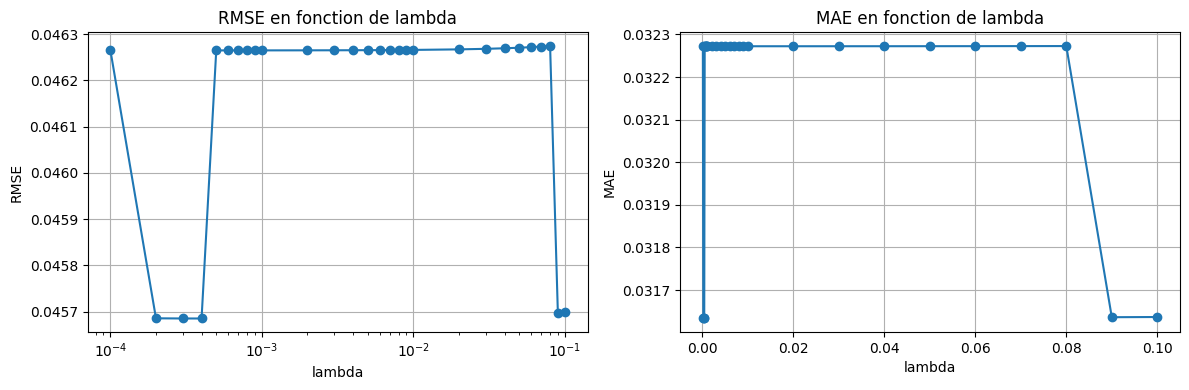

In [42]:
### To run the parametrisation of the problem

results = run_parametrisation_of_model()